In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT / 'src'))

from cevns_pyeft.kernels.basis import coeff_vector_from_triplets, li2026_left_basis_current
from cevns_pyeft.kernels.reconstruction import reconstruct_real_events_from_full_kernel
from cevns_pyeft.experiments.coherent.slow_counts_csi2017 import slow_counts_csi2017

REFERENCE_DIR = ROOT / 'tests' / 'reference_fast_split'
RESPONSES = ROOT / 'data' / 'responses' / 'responses_all.json'
STEM = 'csi2017'
EXPERIMENT = 'CsI2017'
RTOL, ATOL = (2.0e-5, 1.0e-3)


In [2]:
basis = li2026_left_basis_current()
coeff = coeff_vector_from_triplets(basis, {}, include_sm=True)
full_kernel = np.load(REFERENCE_DIR / f'{STEM}_full_kernel.npy')
metadata = __import__('json').loads((REFERENCE_DIR / f'{STEM}_metadata.json').read_text())
raw = reconstruct_real_events_from_full_kernel(full_kernel, coeff)
channel_summed = raw.sum(axis=2)
target_index = metadata['targets'].index('CsI') if 'CsI' in metadata['targets'] else 0
flavor_index = {flavor: metadata['source_flavors'].index(flavor) for flavor in ('mu', 'e', 'mub')}
fast_counts = {flavor: channel_summed[target_index, flavor_index[flavor]] for flavor in ('mu', 'e', 'mub')}
fast_counts['total'] = fast_counts['mu'] + fast_counts['e'] + fast_counts['mub']
slow_counts = slow_counts_csi2017(RESPONSES, include_sm=True, n_enu=6)['counts_per_bin']
pe_bins = np.asarray(metadata['pe_bins'], dtype=float)
centers = 0.5 * (pe_bins[:-1] + pe_bins[1:])
print({k: np.asarray(v, dtype=float) for k, v in fast_counts.items()})


{'mu': array([8.52997435e-09, 6.83199103e-09, 1.19092227e+00, 3.55705035e+00,
       5.73820482e+00, 6.99614045e+00, 6.05863414e+00, 3.27113738e+00,
       4.49263088e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00]), 'e': array([7.72066988e-09, 5.45880225e-09, 9.66744210e-01, 2.96507744e+00,
       4.30245975e+00, 5.71089581e+00, 6.49862252e+00, 6.04676168e+00,
       4.94313904e+00, 3.22523901e+00, 1.45657352e+00, 1.13184586e+00,
       8.50907432e-01, 6.10596866e-01, 4.07566055e-01, 2.37384487e-01,
       9.62727492e-02, 1.35848695e-02, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00]), 'mub': array([8.38974520e-09, 6.52487524e-09, 1.21937866e+00, 3.89030563e+00,
       6

In [3]:
fast_total = np.asarray(fast_counts['total'], dtype=float)
slow_total = np.asarray(slow_counts['total'], dtype=float)
assert fast_total.shape == slow_total.shape == centers.shape
assert np.issubdtype(fast_total.dtype, np.floating)
assert np.all(np.isfinite(fast_total))
assert np.all(np.isfinite(slow_total))
np.testing.assert_allclose(fast_total, slow_total, rtol=RTOL, atol=ATOL)
max_abs_diff = float(np.max(np.abs(fast_total - slow_total)))
summary = {
    'experiment': EXPERIMENT,
    'bins': int(fast_total.size),
    'fast_total': float(np.sum(fast_total)),
    'slow_total': float(np.sum(slow_total)),
    'max_abs_diff': max_abs_diff,
    'status': 'PASS',
}
summary


{'experiment': 'CsI2017',
 'bins': 25,
 'fast_total': 144.19010104208792,
 'slow_total': 144.19041089573065,
 'max_abs_diff': 0.00030985364275792904,
 'status': 'PASS'}

{'experiment': 'CsI2017', 'bins': 25, 'fast_total': 144.19010104208792, 'slow_total': 144.19041089573065, 'max_abs_diff': 0.00030985364275792904, 'status': 'PASS'}


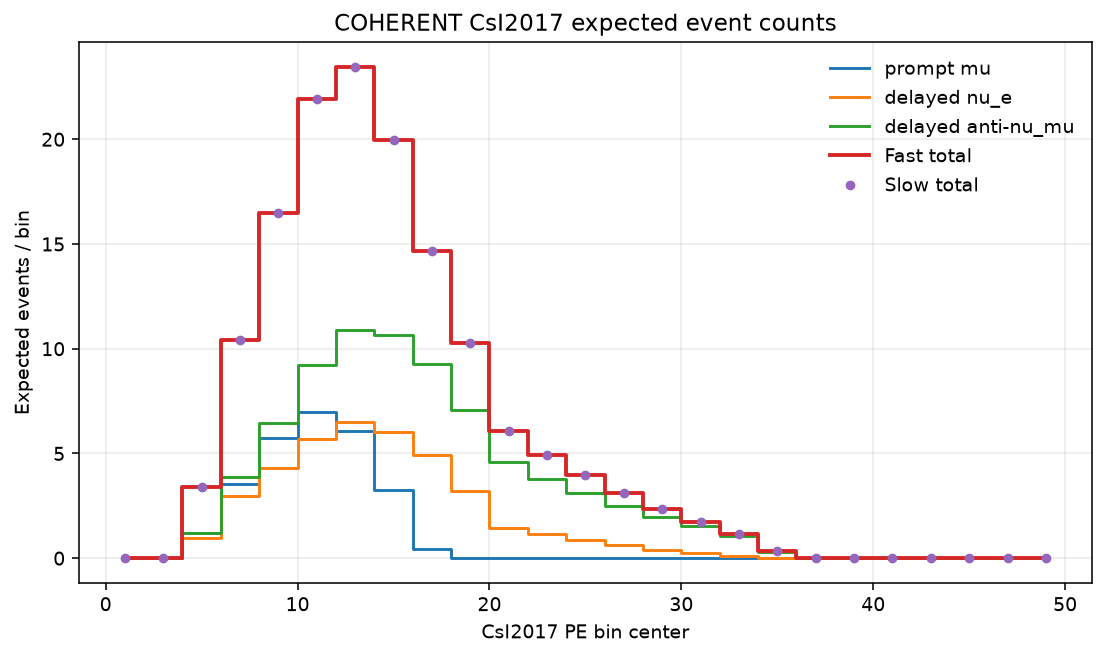

In [4]:
fig, ax = plt.subplots(figsize=(8.0, 4.8), dpi=140)
ax.step(centers, fast_counts['mu'], where='mid', label='prompt mu')
ax.step(centers, fast_counts['e'], where='mid', label='delayed nu_e')
ax.step(centers, fast_counts['mub'], where='mid', label='delayed anti-nu_mu')
ax.step(centers, fast_counts['total'], where='mid', linewidth=2.0, label='Fast total')
ax.plot(centers, slow_counts['total'], 'o', markersize=4.0, label='Slow total')
ax.set_title('COHERENT CsI2017 expected event counts')
ax.set_xlabel('CsI2017 PE bin center')
ax.set_ylabel('Expected events / bin')
ax.grid(True, alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
print(summary)
